In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
import warnings; warnings.filterwarnings('ignore')

## 1. Data Exploration
### Load the dataset

In [2]:
df = pd.read_csv('heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
print('Shape (rows, columns):', df.shape)
df.info()

Shape (rows, columns): (1025, 14)
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


### Features and target variable

In [4]:
feature_desc = {
    'age': 'Age in years',
    'sex': 'Sex (1 = male, 0 = female)',
    'cp': 'Chest pain type (4 values: 0-3)',
    'trestbps': 'Resting blood pressure (mm Hg)',
    'chol': 'Serum cholesterol (mg/dl)',
    'fbs': 'Fasting blood sugar > 120 mg/dl (1 = true, 0 = false)',
    'restecg': 'Resting ECG results (0, 1, 2)',
    'thalach': 'Maximum heart rate achieved',
    'exang': 'Exercise-induced angina (1 = yes, 0 = no)',
    'oldpeak': 'ST depression induced by exercise relative to rest',
    'slope': 'Slope of the peak exercise ST segment',
    'ca': 'Number of major vessels (0-3) colored by fluoroscopy',
    'thal': 'Thalassemia type',
}
features = list(feature_desc.keys())
target = 'target'
print(f'Number of features: {len(features)}')
for f, d in feature_desc.items():
    print(f'  {f:10s} -> {d}')
print(f'\nTarget variable: {target!r} -> heart disease (1 = yes, 0 = no)')

Number of features: 13
  age        -> Age in years
  sex        -> Sex (1 = male, 0 = female)
  cp         -> Chest pain type (4 values: 0-3)
  trestbps   -> Resting blood pressure (mm Hg)
  chol       -> Serum cholesterol (mg/dl)
  fbs        -> Fasting blood sugar > 120 mg/dl (1 = true, 0 = false)
  restecg    -> Resting ECG results (0, 1, 2)
  thalach    -> Maximum heart rate achieved
  exang      -> Exercise-induced angina (1 = yes, 0 = no)
  oldpeak    -> ST depression induced by exercise relative to rest
  slope      -> Slope of the peak exercise ST segment
  ca         -> Number of major vessels (0-3) colored by fluoroscopy
  thal       -> Thalassemia type

Target variable: 'target' -> heart disease (1 = yes, 0 = no)


### Summary statistics

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


### Target class balance

target
1    526
0    499
Name: count, dtype: int64


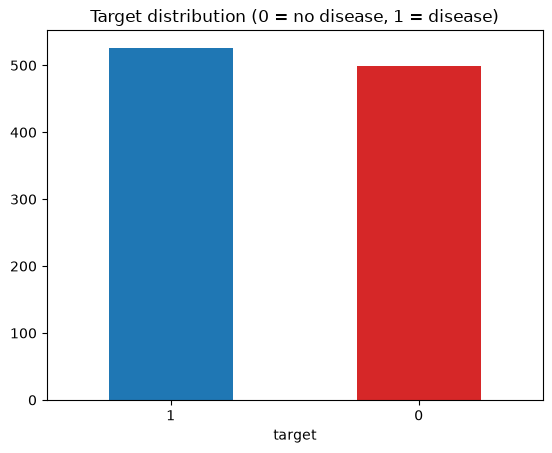

In [6]:
print(df['target'].value_counts())
df['target'].value_counts().plot(kind='bar', color=['tab:blue', 'tab:red'])
plt.title('Target distribution (0 = no disease, 1 = disease)'); plt.xticks(rotation=0); plt.show()

### Unique values of categorical features

In [7]:
categorical = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
numerical = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
for c in categorical:
    print(f'{c:8s}', sorted(df[c].unique()))

sex      [np.int64(0), np.int64(1)]
cp       [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
fbs      [np.int64(0), np.int64(1)]
restecg  [np.int64(0), np.int64(1), np.int64(2)]
exang    [np.int64(0), np.int64(1)]
slope    [np.int64(0), np.int64(1), np.int64(2)]
ca       [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
thal     [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


### Distributions of numerical features by target

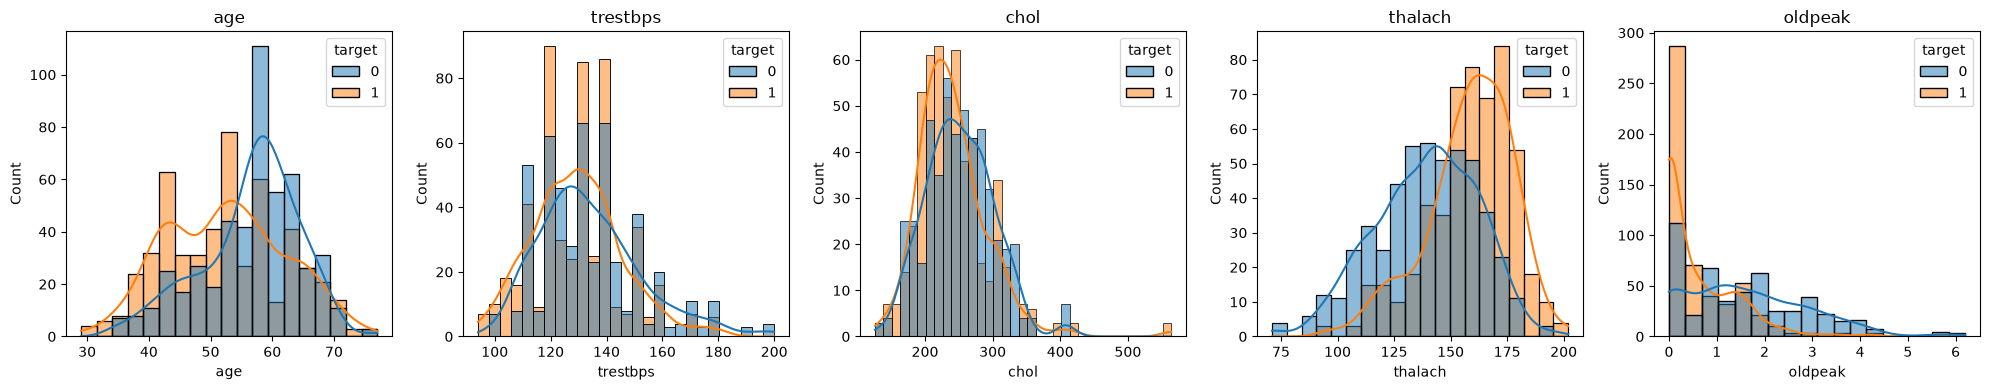

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, numerical):
    sns.histplot(data=df, x=col, hue='target', kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

### Categorical features vs target

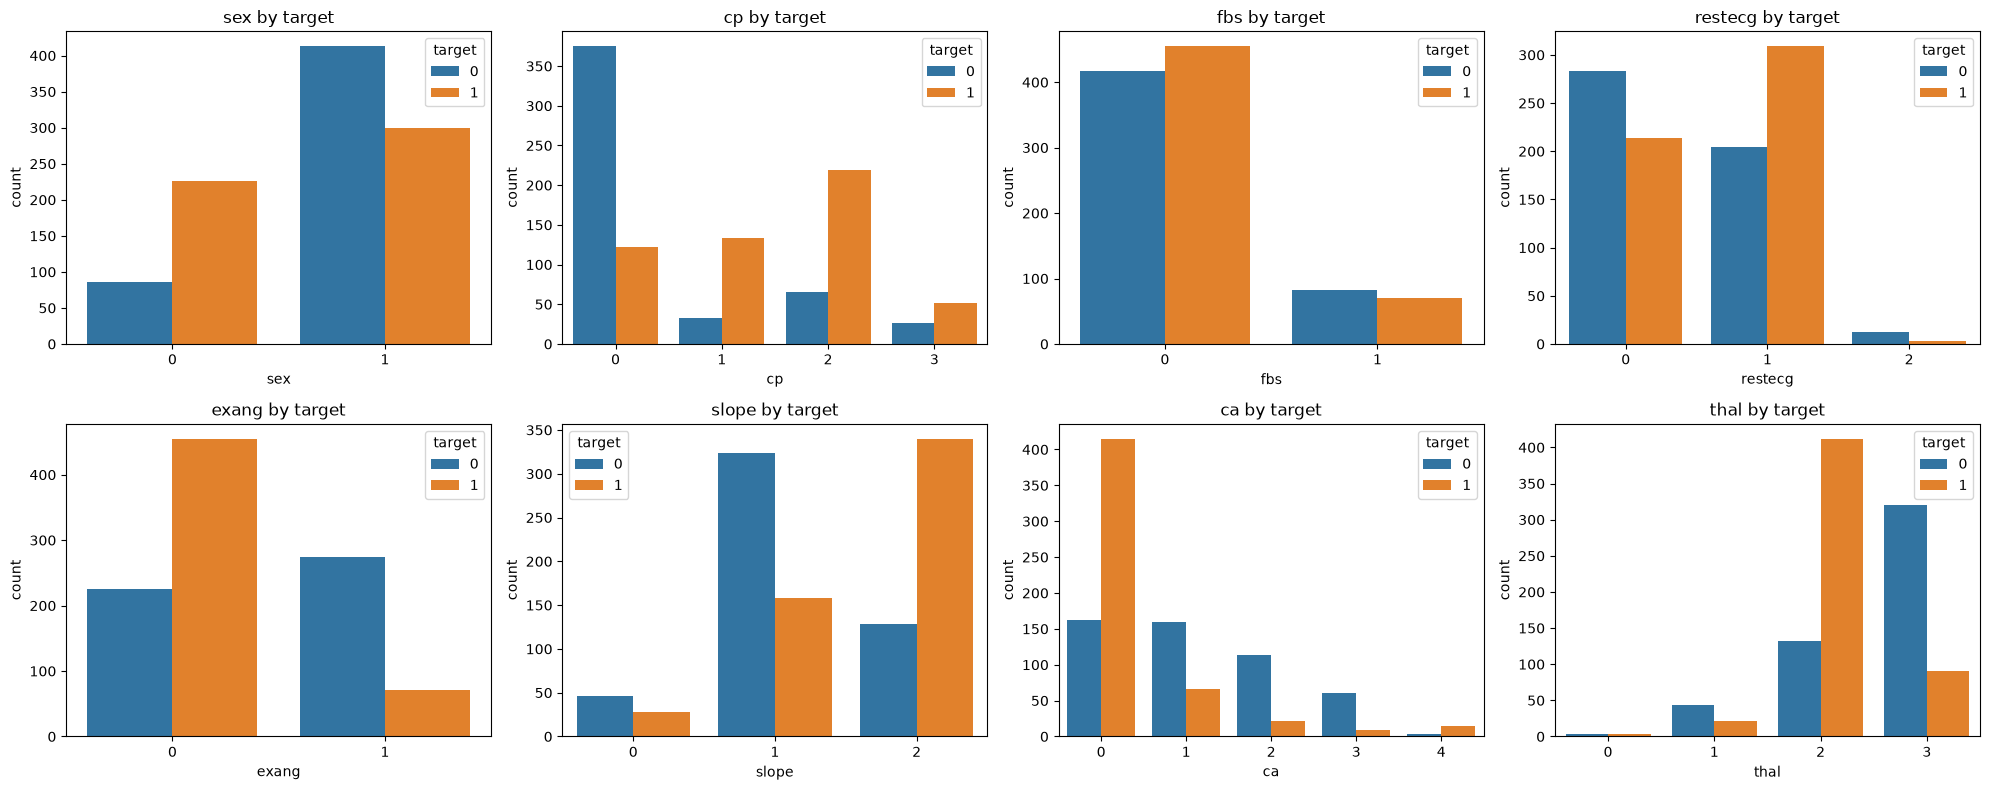

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), categorical):
    sns.countplot(data=df, x=col, hue='target', ax=ax)
    ax.set_title(f'{col} by target')
plt.tight_layout(); plt.show()

### Age vs maximum heart rate

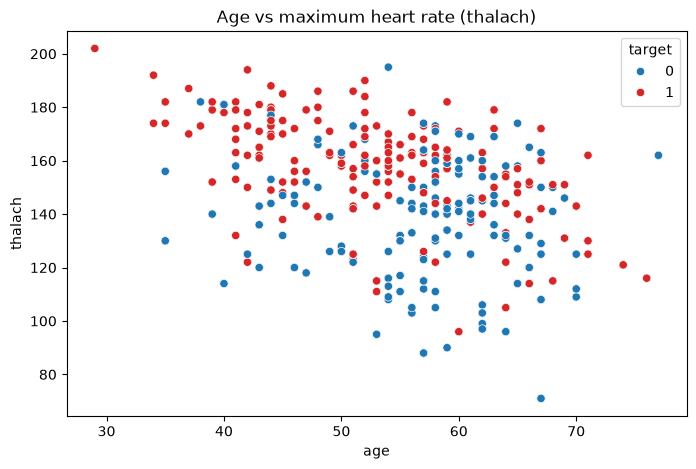

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='age', y='thalach', hue='target', palette={0: 'tab:blue', 1: 'tab:red'})
plt.title('Age vs maximum heart rate (thalach)'); plt.show()

### Correlation heatmap

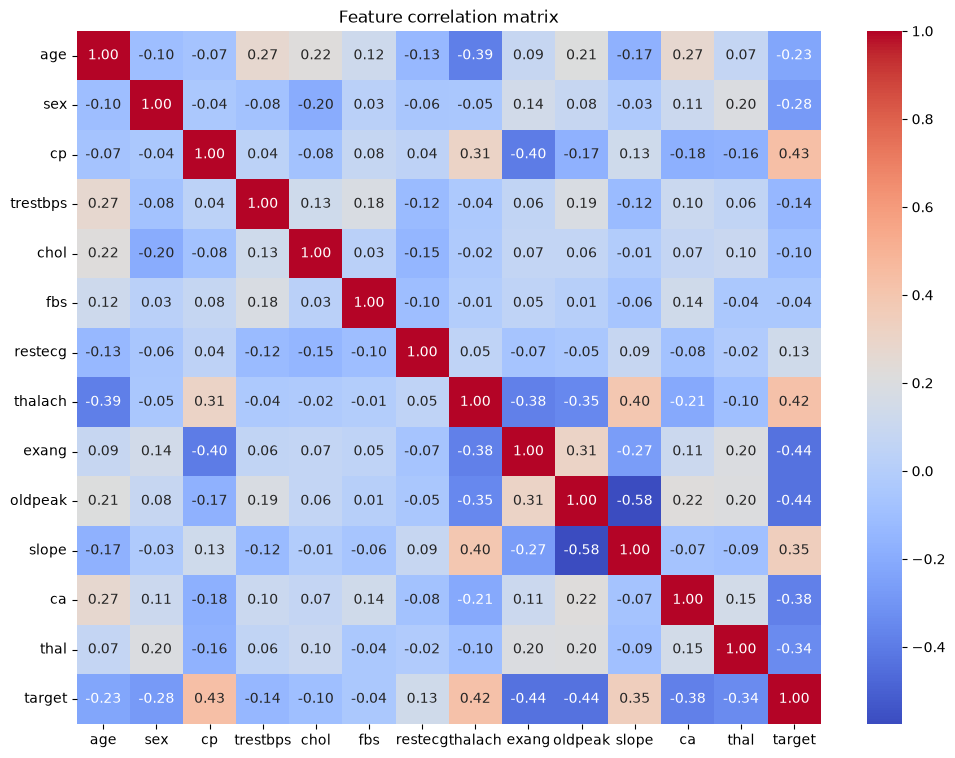

Correlation with target:
cp          0.434854
thalach     0.422895
slope       0.345512
restecg     0.134468
fbs        -0.041164
chol       -0.099966
trestbps   -0.138772
age        -0.229324
sex        -0.279501
thal       -0.337838
ca         -0.382085
exang      -0.438029
oldpeak    -0.438441
Name: target, dtype: float64


In [11]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature correlation matrix'); plt.show()
print('Correlation with target:')
print(df.corr()['target'].drop('target').sort_values(ascending=False))

**Key observations:** `cp`, `thalach` and `slope` are positively correlated with heart disease, while `exang`, `oldpeak`, `ca`, `thal` and `sex` are negatively correlated. No pair of features is extremely correlated, so multicollinearity (a logistic regression assumption from the lecture) is not a major concern.

## 2. Data Preprocessing
### Missing values

In [12]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

There are no `NaN` values, but the dataset has **hidden invalid values**:
- `ca` should be 0–3, but some rows have `4`
- `thal` per the description is 1, 2, 3 (0 means not recorded)

We treat those as missing and fill them with the column **mode** (most frequent value).

In [13]:
print('Rows with ca == 4  :', (df['ca'] == 4).sum())
print('Rows with thal == 0:', (df['thal'] == 0).sum())

df['ca'] = df['ca'].replace(4, np.nan)
df['thal'] = df['thal'].replace(0, np.nan)
print('\nMissing after marking invalid values:')
print(df[['ca', 'thal']].isnull().sum())

for c in ['ca', 'thal']:
    df[c] = df[c].fillna(df[c].mode()[0]).astype(int)
print('\nMissing after imputation:', df.isnull().sum().sum())

Rows with ca == 4  : 18
Rows with thal == 0: 7

Missing after marking invalid values:
ca      18
thal     7
dtype: int64

Missing after imputation: 0


### Duplicate rows

In [14]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)

Duplicate rows: 723
Shape after removing duplicates: (302, 14)


### Split features (X) and target (y), then train/test split

In [15]:
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (241, 13)  Test: (61, 13)


### Normalize (standardize) numerical features
The scaler is fit **only on the training data** to avoid data leakage.

In [16]:
scaler = StandardScaler()
X_train[numerical] = scaler.fit_transform(X_train[numerical])
X_test[numerical] = scaler.transform(X_test[numerical])
X_train[numerical].describe().loc[['mean', 'std']].round(2)

,age,trestbps,chol,thalach,oldpeak
mean,-0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


## 3. Modeling: Logistic Regression
Logistic regression passes a linear combination of the features through the **sigmoid** function, giving a probability between 0 and 1. Probability of 0.5 or more means class 1 (disease), otherwise class 0.

In [17]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

pd.DataFrame({'actual': y_test.values[:10], 'predicted': y_pred[:10],
              'P(disease)': y_prob[:10].round(3)})

,actual,predicted,P(disease)
0,0,0,0.218
1,0,1,0.716
2,0,0,0.006
3,0,1,0.622
4,0,1,0.926
5,0,0,0.007
6,1,1,0.839
7,0,0,0.028
8,1,1,0.978
9,0,0,0.451


## 4. Evaluation
### Accuracy, Precision, Recall, F1-score

In [18]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print(f'Train accuracy: {model.score(X_train, y_train):.3f}')
print(f'Test accuracy : {acc:.3f}')
print(f'Precision     : {prec:.3f}')
print(f'Recall        : {rec:.3f}')
print(f'F1-score      : {f1:.3f}')

Train accuracy: 0.876
Test accuracy : 0.820
Precision     : 0.824
Recall        : 0.848
F1-score      : 0.836


### Confusion matrix

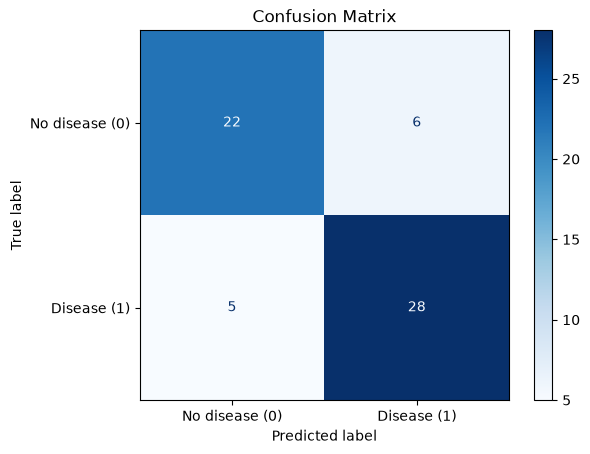

TP = 28, TN = 22, FP = 6, FN = 5
Accuracy    = (TP+TN)/total = 0.820
Precision   = TP/(TP+FP)    = 0.824
Recall      = TP/(TP+FN)    = 0.848
Specificity = TN/(TN+FP)    = 0.786


In [19]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['No disease (0)', 'Disease (1)']).plot(cmap='Blues')
plt.title('Confusion Matrix'); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'TP = {tp}, TN = {tn}, FP = {fp}, FN = {fn}')
print(f'Accuracy    = (TP+TN)/total = {(tp+tn)/cm.sum():.3f}')
print(f'Precision   = TP/(TP+FP)    = {tp/(tp+fp):.3f}')
print(f'Recall      = TP/(TP+FN)    = {tp/(tp+fn):.3f}')
print(f'Specificity = TN/(TN+FP)    = {tn/(tn+fp):.3f}')

### Classification report

In [20]:
print(classification_report(y_test, y_pred, target_names=['No disease', 'Disease']))

              precision    recall  f1-score   support

  No disease       0.81      0.79      0.80        28
     Disease       0.82      0.85      0.84        33

    accuracy                           0.82        61
   macro avg       0.82      0.82      0.82        61
weighted avg       0.82      0.82      0.82        61



### Metrics summary chart

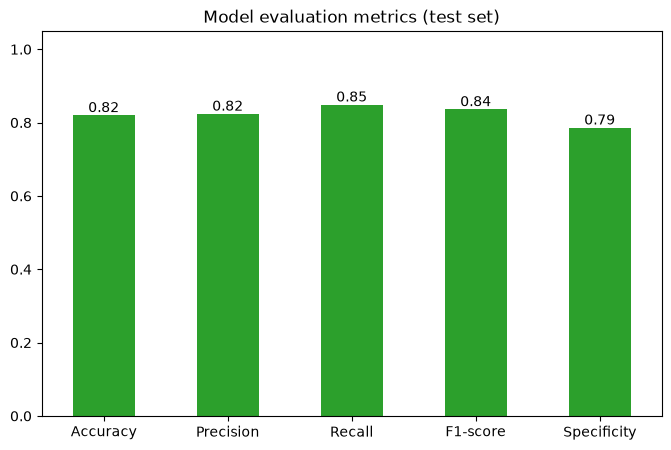

In [21]:
metrics = pd.Series({'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-score': f1,
                     'Specificity': tn / (tn + fp)})
ax = metrics.plot(kind='bar', color='tab:green', figsize=(8, 5))
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.ylim(0, 1.05); plt.xticks(rotation=0); plt.title('Model evaluation metrics (test set)'); plt.show()

## Conclusion
- **Target variable:** `target` (1 = heart disease, 0 = no disease), a **binary classification** problem with 13 input features.
- **Preprocessing:** invalid `ca`/`thal` values treated as missing and filled with the mode, duplicate rows removed, numerical features normalized with `StandardScaler`.
- **Model:** Logistic Regression. See the metrics above (accuracy, precision, recall, F1, specificity) and the confusion matrix.
- In a medical setting **recall** matters most: a false negative (missing a sick patient) is costlier than a false positive.